#RCA Activity: Titanic Survival Prediction using Logistic Regression

**Objective:** Predict whether a Titanic passenger survived or did not survive using Logistic Regression.

**Dataset:** [Titanic dataset](https://github.com/mwaskom/seaborn-data/blob/master/titanic.csv)


## 1. Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay

sns.set_theme(style="whitegrid")

## 2. Load dataset

In [ ]:

df = pd.read_csv("titanic.csv")

Dataset shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 3. Inspect the data

In [ ]:
display(df.head())
display(df.tail())
print("Columns:", df.columns.tolist())
df.info()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


Columns: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2

In [ ]:
display(df.describe())
display(df.describe(include="object"))

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


,sex,embarked,class,who,deck,embark_town,alive
count,891,889,891,891,203,889,891
unique,2,3,3,3,7,3,2
top,male,S,Third,man,C,Southampton,no
freq,577,644,491,537,59,644,549


## 4. Select features and target

Input features: passenger class, sex, age, siblings/spouses, parents/children, fare and embarkation port.

In [ ]:
features = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
target = "survived"

data = df[features + [target]].dropna(subset=[target]).copy()
data[target] = data[target].astype(int)
X = data[features]
y = data[target]
print("Selected data shape:", data.shape)
print("Target counts:")
display(y.value_counts())

Selected data shape: (891, 8)
Target counts:


,count
survived,
0,549
1,342


## 5. Missing values and duplicates

In [ ]:
missing = pd.DataFrame({
    "Missing Count": data.isnull().sum(),
    "Missing Percentage": (data.isnull().mean() * 100).round(2)
})
display(missing)
print("Duplicate rows:", data.duplicated().sum())

,Missing Count,Missing Percentage
pclass,0,0.00
sex,0,0.00
age,177,19.87
sibsp,0,0.00
parch,0,0.00
fare,0,0.00
embarked,2,0.22
survived,0,0.00


Duplicate rows: 111


## 6. Exploratory Data Analysis

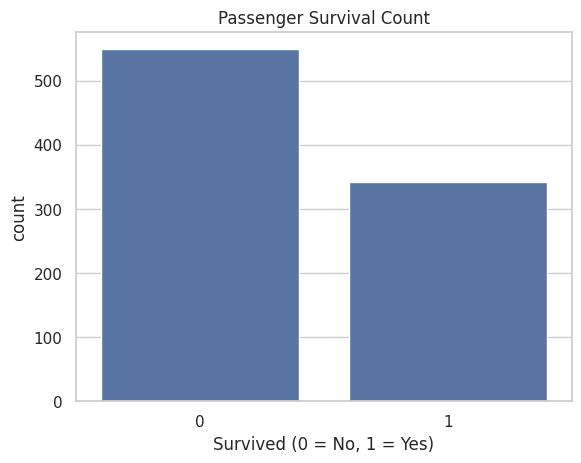

In [ ]:
sns.countplot(data=data, x="survived")
plt.title("Passenger Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.show()

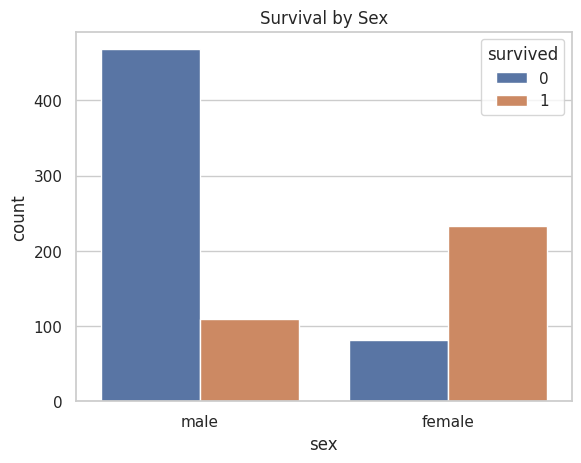

In [ ]:
sns.countplot(data=data, x="sex", hue="survived")
plt.title("Survival by Sex")
plt.show()

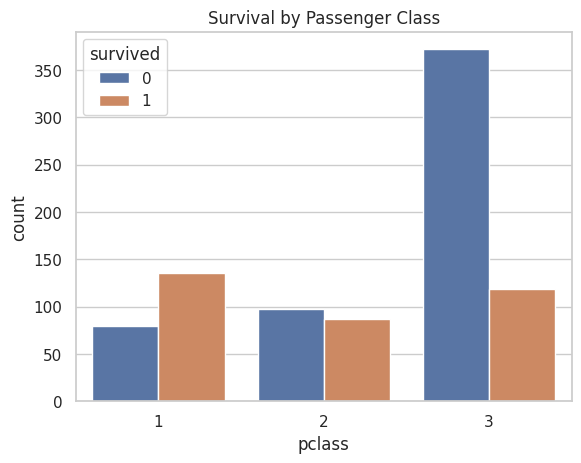

In [ ]:
sns.countplot(data=data, x="pclass", hue="survived")
plt.title("Survival by Passenger Class")
plt.show()

## 7. Preprocess features

In [ ]:
numeric_features = ["age", "sibsp", "parch", "fare"]
categorical_features = ["pclass", "sex", "embarked"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])
print("Preprocessing pipeline created.")

Preprocessing pipeline created.


## 8. Split into training and testing sets

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 712
Testing rows: 179


## 9. Train Logistic Regression model

In [ ]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])
model.fit(X_train, y_train)
print("Model trained successfully.")

Model trained successfully.


## 10. Predict on test data

In [ ]:
y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]

display(pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
}).head(10))

,Actual,Predicted
0,0,0
1,0,0
2,1,0
3,0,0
4,1,1
5,1,0
6,1,1
7,0,0
8,0,0
9,0,0


## 11. Evaluate the model

In [ ]:
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_probability), 4))

Accuracy: 0.8045
Precision: 0.7931
Recall: 0.6667
F1-score: 0.7244
ROC-AUC: 0.8427



- Accuracy: proportion of all predictions that are correct.
- Precision: among predicted survivors, the proportion who actually survived.
- Recall: among actual survivors, the proportion identified by the model.
- F1-score: harmonic balance of precision and recall.
- ROC-AUC: ability to separate the two classes across different thresholds.

## 12. Confusion matrix

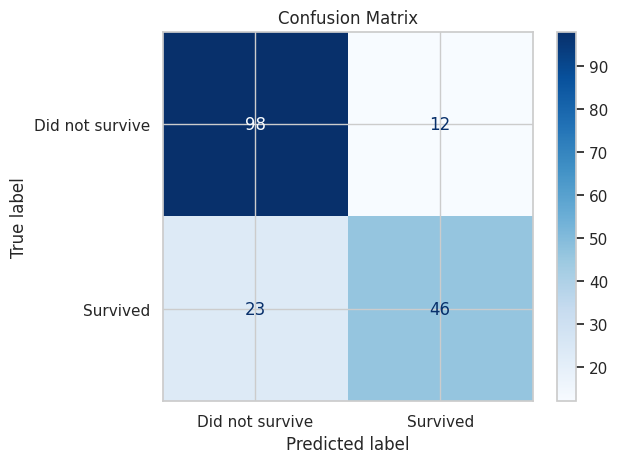

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Did not survive", "Survived"],
    cmap="Blues"
)
plt.title("Confusion Matrix")
plt.show()

## 13. ROC curve

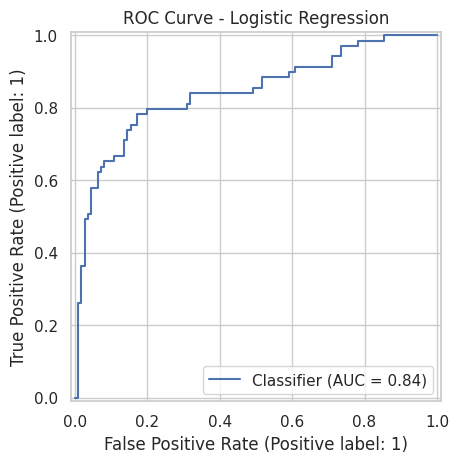

In [ ]:
RocCurveDisplay.from_predictions(y_test, y_probability)
plt.title("ROC Curve - Logistic Regression")
plt.show()

## 14. Predict for a new passenger

In [ ]:
new_passenger = pd.DataFrame([{
    "pclass": 3,
    "sex": "male",
    "age": 25,
    "sibsp": 0,
    "parch": 0,
    "fare": 8.05,
    "embarked": "S"
}])

prediction = model.predict(new_passenger)[0]
probability = model.predict_proba(new_passenger)[0][1]

print("Predicted class:", prediction)
print(f"Estimated survival probability: {probability:.2%}")
if prediction == 1:
    print("Prediction: Passenger is predicted to survive.")
else:
    print("Prediction: Passenger is predicted not to survive.")

Predicted class: 0
Estimated survival probability: 9.91%
Prediction: Passenger is predicted not to survive.


## 15. Save selected dataset

In [ ]:
data.to_csv("Titanic_Logistic_Regression_Data.csv", index=False)
print("Saved as Titanic_Logistic_Regression_Data.csv")

Saved as Titanic_Logistic_Regression_Data.csv


## 16. Conclusion

A Logistic Regression classification model was developed to predict Titanic passenger survival. The dataset was inspected, missing values were handled, categorical features were encoded, numerical features were scaled, and the data was split into training and testing sets. The model was evaluated using accuracy, precision, recall, F1-score, confusion matrix and ROC-AUC.

The model's performance depends on the selected features and this historical dataset. Its predictions are estimates, not certain outcomes.

